# Train a paddle from scratch
Run the experiment behind the project-page replay. Seed 101 fixes connectivity and random streams. The actor trains on 320 serves and takes two matched 100-serve tests, once before training and once afterward. Evaluation uses fresh serves from a separate random stream and freezes all learning.

A trial ends at the first paddle encounter. A hit earns +1 and a miss earns −1. During the serve, a change in ball–paddle alignment also contributes to the training reward. The state potential is $\Phi=-|y_{\rm ball}-y_{\rm paddle}|$, with zero terminal potential.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from model import LearningConfig, run_learning

config = LearningConfig()
run = run_learning(config, seed=101, record=True)
for phase in ('before', 'after'):
    print(f'{phase:>6}: {run[phase]["success_fraction"]:.0%} of {config.eval_trials} held-out serves')
np.testing.assert_array_equal(run['before']['recurrent_weights'], run['after']['recurrent_weights'])

before: 25% of 100 held-out serves
 after: 84% of 100 held-out serves


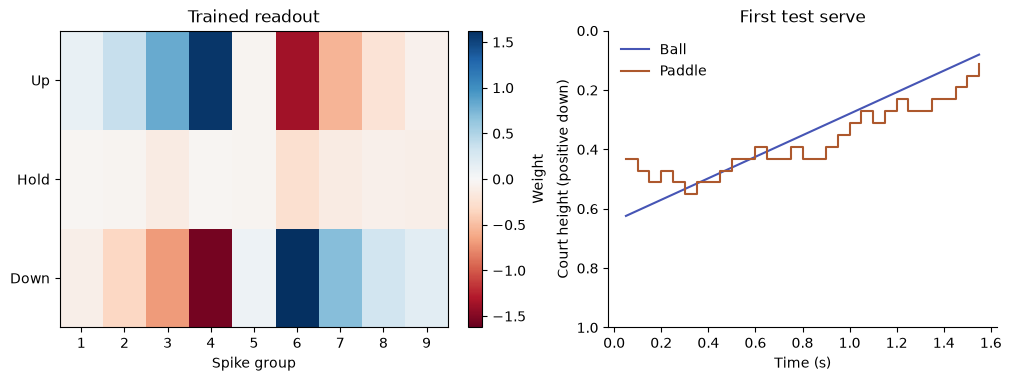

In [2]:
weights = run['learned_weights'][:, :-1]  # The last column contains action biases.
limit = np.abs(weights).max()
first_serve = [frame for frame in run['after']['frames'] if frame['trial'] == 0]
t = [frame['t'] for frame in first_serve]
fig, (policy, game) = plt.subplots(1, 2, figsize=(10, 3.7), layout='constrained')
im = policy.imshow(weights, cmap='RdBu', vmin=-limit, vmax=limit, aspect='auto')
policy.set(xticks=np.arange(9), xticklabels=np.arange(1, 10), xlabel='Spike group',
           yticks=[0, 1, 2], yticklabels=['Up', 'Hold', 'Down'], title='Trained readout')
fig.colorbar(im, ax=policy, label='Weight')
game.plot(t, [f['ball'][1] for f in first_serve], color='#4655b5', label='Ball')
game.step(t, [f['paddle'] for f in first_serve], where='post', color='#ad582d', label='Paddle')
game.set(xlabel='Time (s)', ylabel='Court height (positive down)', ylim=(1, 0), title='First test serve')
game.legend(frameon=False)
game.spines[['top', 'right']].set_visible(False)
plt.show()

Each column of the heatmap shows how one spike group affects the three action scores. On the website, the pruning animation removes small weights from a display copy. This notebook and the benchmark use the complete trained readout. [Watch the project-page replay](https://iamnikhiliyer.com/projects/closed-loop-neural-interfaces-with-ai/#simulation).